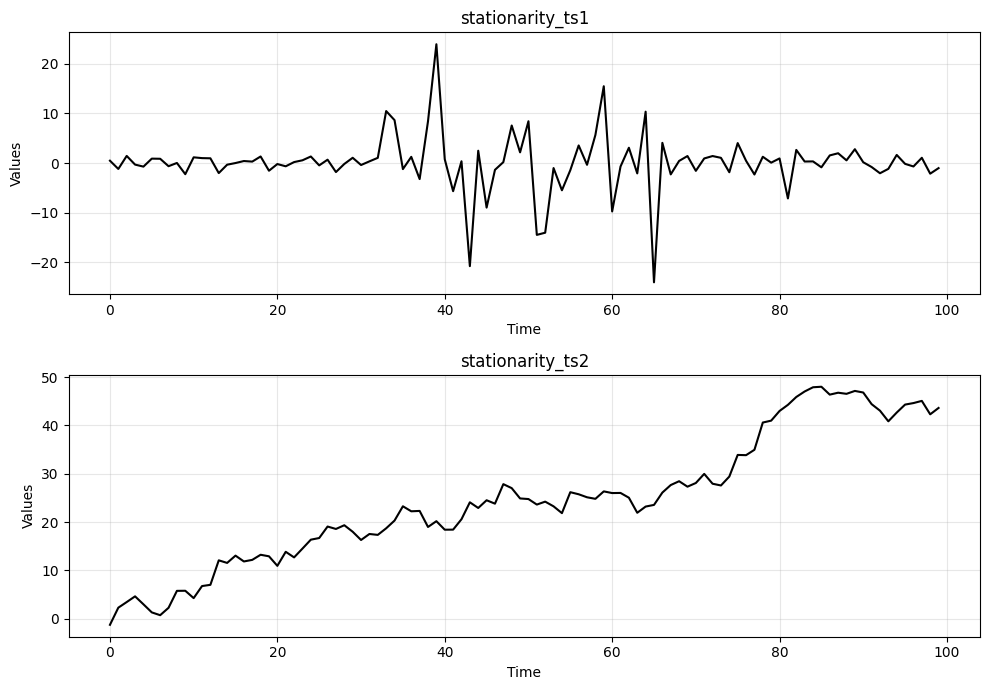

In [1]:
 # Упражнение 1
import requests
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt

# Загрузка данных
response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts1.npy?download=1")
response.raise_for_status()
stationarity_ts1 = np.load(BytesIO(response.content))

response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts2.npy?download=1")
response.raise_for_status()
stationarity_ts2 = np.load(BytesIO(response.content))

# Функция для построения графиков
def run_sequence_plot(x, y, title, xlabel="Time", ylabel="Values", ax=None):
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(10, 3.5))
    ax.plot(x, y, 'k-')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    return ax

# Построение двух временных рядов
time = np.arange(len(stationarity_ts1))

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
run_sequence_plot(time, stationarity_ts1, title="stationarity_ts1", ax=axes[0])
run_sequence_plot(time, stationarity_ts2, title="stationarity_ts2", ax=axes[1])
plt.tight_layout()
plt.show()

stationarity_ts1: На графике видно, что дисперсия (амплитуда колебаний) не постоянна. В середине ряда происходят сильные выбросы и колебания, которых нет в начале и конце.Вывод: Ряд нестационарен из-за нарушения условия постоянной дисперсии.

stationarity_ts2: На графике заметен четкий восходящий тренд (среднее значение растет со временем). Также видно, что амплитуда колебаний (дисперсия) увеличивается по мере роста значений. Вывод: Ряд нестационарный (нарушены условия постоянного среднего и постоянной дисперсии).

Сводная статистика по фрагментам:

Ряд ts1 (разбит на 4 части)
Часть 1: Среднее = 0.04, Стд. отклонение = 1.03
Часть 2: Среднее = 1.01, Стд. отклонение = 7.73
Часть 3: Среднее = -0.93, Стд. отклонение = 8.16
Часть 4: Среднее = 0.05, Стд. отклонение = 2.17

Ряд ts2 (разбит на 4 части)
Часть 1: Среднее = 8.07, Стд. отклонение = 5.19
Часть 2: Среднее = 20.87, Стд. отклонение = 3.23
Часть 3: Среднее = 25.78, Стд. отклонение = 2.20
Часть 4: Среднее = 43.40, Стд. отклонение = 4.07
Гистограммы:



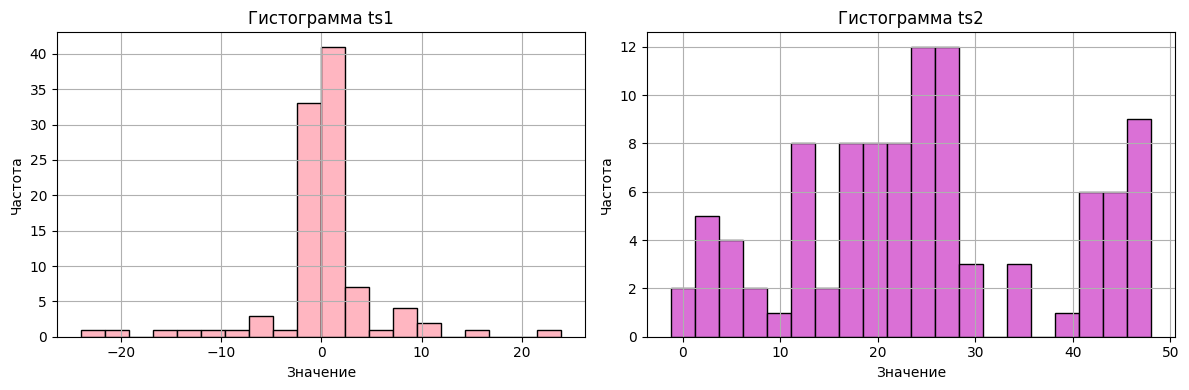


Расширенный тест Дики-Фуллера(ADF)

Результат для ts1:
ADF-статистика: -3.0324
p-value: 0.0320
Критические значения:
  1%: -3.5043
  5%: -2.8939
  10%: -2.5840

Результат для ts2:
ADF-статистика: -1.3223
p-value: 0.6189
Критические значения:
  1%: -3.4982
  5%: -2.8912
  10%: -2.5826


In [2]:
# Упражнение 2
import requests
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import warnings

warnings.filterwarnings('ignore')

# Загрузка данных
response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts1.npy?download=1")
stationarity_ts1 = np.load(BytesIO(response.content))

response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts2.npy?download=1")
stationarity_ts2 = np.load(BytesIO(response.content))
df = pd.DataFrame({'ts1': stationarity_ts1, 'ts2': stationarity_ts2})


# Сводная статистика по фрагментам
print("Сводная статистика по фрагментам:")
print("\nРяд ts1 (разбит на 4 части)")
for i, chunk in enumerate(np.array_split(df['ts1'], 4), 1):
    print(f"Часть {i}: Среднее = {chunk.mean():.2f}, Стд. отклонение = {chunk.std():.2f}")
print("\nРяд ts2 (разбит на 4 части)")
for i, chunk in enumerate(np.array_split(df['ts2'], 4), 1):
    print(f"Часть {i}: Среднее = {chunk.mean():.2f}, Стд. отклонение = {chunk.std():.2f}")

# Гистограммы
print("Гистограммы:\n")
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
df['ts1'].hist(bins=20, color='lightpink', edgecolor='black')
plt.title('Гистограмма ts1')
plt.xlabel('Значение')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
df['ts2'].hist(bins=20, color='orchid', edgecolor='black')
plt.title('Гистограмма ts2')
plt.xlabel('Значение')
plt.ylabel('Частота')

plt.tight_layout()
plt.show()


# Расширенный тест Дики-Фуллера (ADF)
print("\nРасширенный тест Дики-Фуллера(ADF)")

def run_adf_test(series, name):
    result = adfuller(series, autolag='AIC')
    print(f"\nРезультат для {name}:")
    print(f"ADF-статистика: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print("Критические значения:")
    for key, value in result[4].items():
        print(f"  {key}: {value:.4f}")

run_adf_test(df['ts1'], "ts1")
run_adf_test(df['ts2'], "ts2")

Сводная статистика по фрагментам:

Ряд ts1: Среднее значение остается относительно стабильным во всех четырех частях (колеблется около 0). Однако стандартное отклонение меняется кардинально: в 1-й и 4-й частях оно составляет около 1–2, а во 2-й и 3-й частях резко возрастает до 7.7 и 8.1. Это указывает на гетероскедастичность (непостоянство дисперсии).

Ряд ts2: Наблюдается ярко выраженное изменение обоих показателей. Среднее значение неуклонно растет от части к части (с 8.07 до 43.40), а стандартное отклонение также меняется. Это указывает на наличие восходящего тренда и меняющейся дисперсии.

Гистограммы:

ts1: Распределение имеет ярко выраженный узкий пик около нуля, но также присутствуют длинные «хвосты» в обе стороны (выбросы). Наличие выбросов и меняющейся дисперсии (подтвержденной статистикой) говорит о том, что распределение не является нормальным и стабильным во времени.

ts2: Гистограмма имеет несколько пиков (мультимодальность) и равномерно размазана по широкому диапазону от 0 до 50. Это классический признак смешивания данных из разных временных периодов, когда среднее значение сдвигается (тренд).

Расширенный тест Дики-Фуллера (ADF):

Для ts1: p-value = 0.0320 (< 0.05). Мы отвергаем нулевую гипотезу. С точки зрения теста ADF, ряд стационарен по среднему (нет единичного корня/тренда). Однако ADF не проверяет дисперсию, поэтому нестационарность из-за гетероскедастичности он не уловил.

Для ts2: p-value = 0.6189 (> 0.05). Мы не можем отвергнуть нулевую гипотезу. Ряд нестационарен (присутствует единичный корень / тренд).

Общий итог:

Ряд ts1 формально стационарен по среднему (согласно ADF), но нестационарен из-за непостоянной дисперсии (гетероскедастичность).

Ряд ts2 нестационарен (имеет тренд).

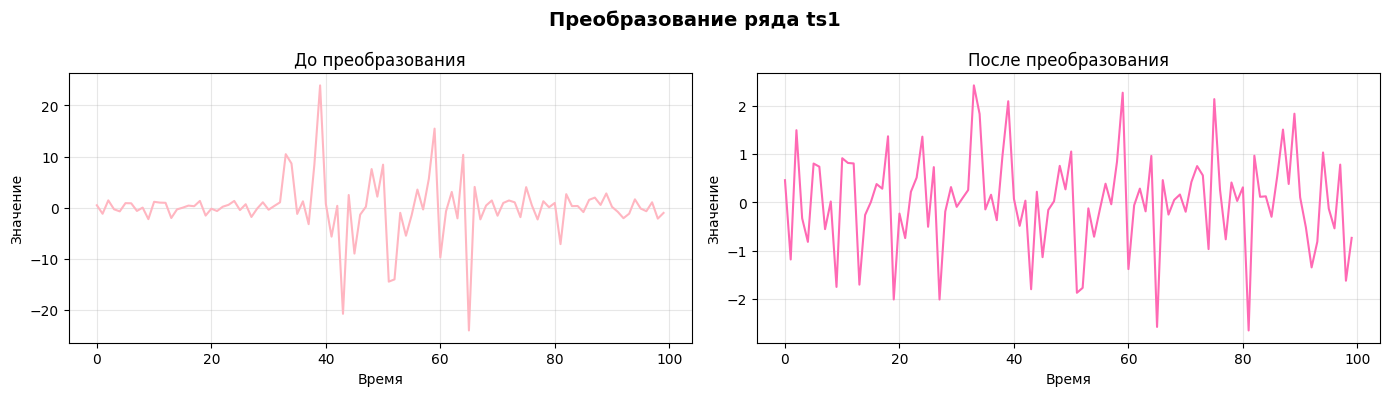


ADF-тест для ts1:
ADF-статистика: -10.5634
p-value: 0.0000
Ряд стационарен



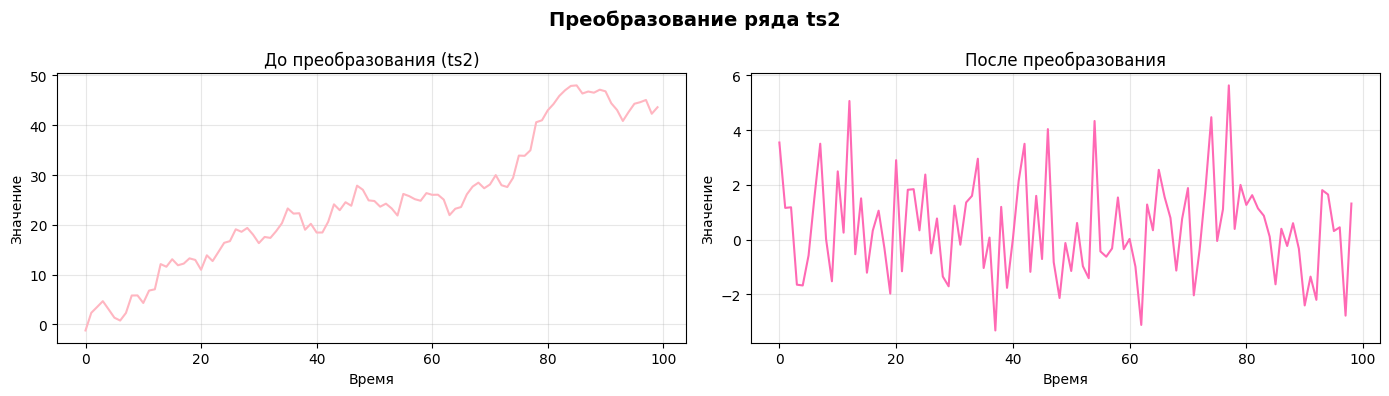


ADF-тест для ts2:
ADF-статистика: -10.2800
p-value: 0.0000
Ряд стационарен



In [3]:
# Упражнение 3

import requests
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import warnings

warnings.filterwarnings('ignore')

# Загрузка данных
response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts1.npy?download=1")
stationarity_ts1 = np.load(BytesIO(response.content), allow_pickle=True)

response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts2.npy?download=1")
stationarity_ts2 = np.load(BytesIO(response.content), allow_pickle=True)

# Преобразования
new_ts1 = stationarity_ts1 - stationarity_ts1.min() + 1.0
log_ts1 = np.log(new_ts1)
rolling_std_ts1 = pd.Series(stationarity_ts1).rolling(window=10, center=True, min_periods=1).std().values
ts1_transformed = stationarity_ts1 / rolling_std_ts1

ts2_transformed = np.diff(stationarity_ts2)

# Функция для вывода ADF-теста
def run_adf_test(series, name):
    result = adfuller(series, autolag='AIC')
    print(f"ADF-тест для {name}:")
    print(f"ADF-статистика: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    if result[1] < 0.05:
        print("Ряд стационарен\n")
    else:
        print("Ряд не стационарен\n")

plt.figure(figsize=(14, 4))
plt.suptitle('Преобразование ряда ts1', fontsize=14, fontweight='bold')

plt.subplot(1, 2, 1)
plt.plot(stationarity_ts1, color='lightpink', linewidth=1.5)
plt.title('До преобразования')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(np.arange(len(ts1_transformed)), ts1_transformed, color='hotpink', linewidth=1.5)
plt.title('После преобразования')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
print()
run_adf_test(ts1_transformed, "ts1")

plt.figure(figsize=(14, 4))
plt.suptitle('Преобразование ряда ts2', fontsize=14, fontweight='bold')

plt.subplot(1, 2, 1)
plt.plot(stationarity_ts2, color='lightpink', linewidth=1.5)
plt.title('До преобразования (ts2)')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(np.arange(len(ts2_transformed)), ts2_transformed, color='hotpink', linewidth=1.5)
plt.title('После преобразования')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
print()
run_adf_test(ts2_transformed, "ts2")

Преобразование ряда ts1 (Нормализация на центрированное скользящее стандартное отклонение):

Исходный ряд ts1 колеблется вокруг нуля, поэтому классическое логарифмирование к нему неприменимо (оно лишь усиливает разброс из-за асимптоты около нуля). Главная проблема этого ряда — ярко выраженная гетероскедастичность (дисперсия сильно «прыгает» в середине ряда). Чтобы стабилизировать дисперсию, мы применили нормализацию: разделили исходный ряд на его локальное (скользящее) стандартное отклонение с окном 10.

Результат: На графике «После преобразования» видно, что амплитуда колебаний стала абсолютно ровной по всей длине ряда, а выбросы больше не дестабилизируют картину. ADF-тест показал p-value = 0.0000. Нулевая гипотеза отвергается, ряд успешно приведен к стационарному виду.

Преобразование ряда ts2 (Разность 1-го порядка):

Исходный ряд ts2 имеет ярко выраженный долгосрочный восходящий тренд (среднее значение неуклонно растет). Для устранения этой нестационарности в среднем достаточно применить обычное дифференцирование (разность первого порядка), которое вычитает предыдущее значение из текущего.

Результат: На графике «После преобразования» тренд полностью исчез, и ряд превратился в стационарный процесс, колеблющийся вокруг нуля. ADF-тест: p-value = 0.0000. Ряд также признан стационарным.

Общий итог:
Оба временных ряда были успешно приведены к стационарному виду. Для ts1 мы устранили проблему непостоянной дисперсии (гетероскедастичности) через нормализацию на скользящее стандартное отклонение. Для ts2 был устранен линейный тренд с помощью дифференцирования. Тест ADF для обоих рядов подтвердил стационарность (p-value < 0.05), а визуальный анализ графиков — отсутствие трендов, постоянное среднее (около нуля) и стабилизацию амплитуды.

